<a href="https://colab.research.google.com/github/dreamer8848/Big-Data-Analytics/blob/main/Data_preprocessing_and_hypothesis_testing_big_data_week_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
cd /content/drive/MyDrive/Colab Notebooks/Big Data

/content/drive/MyDrive/Colab Notebooks/Big Data


In [42]:
!pip install missingno -q



In [43]:
import numpy as np                          # maths and arrays
import pandas as pd                         # tables (DataFrames)
import missingno as msno                    # visualise missing data
import matplotlib.pyplot as plt             # basic charts
import seaborn as sns                       # prettier charts
import scipy.stats as stats                 # statistical tests
from scipy.stats import chi2_contingency    # chi-squared test
import os                                   # file system tools

print("All libraries imported successfully!")

All libraries imported successfully!


In [46]:
from google.colab import files
uploaded = files.upload()   # click "Choose Files" → select Marketing_data.csv

Saving Marketing_data.csv to Marketing_data.csv


In [47]:
import io
data = pd.read_csv(io.BytesIO(uploaded['Marketing_data.csv']))

print("Dataset loaded!")
print("Rows:", data.shape[0])      # number of customers
print("Columns:", data.shape[1])   # number of features

Dataset loaded!
Rows: 2240
Columns: 28


In [48]:
data.head()   # shows the first 5 rows

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP


In [49]:
print(data.dtypes)

ID                      int64
Year_Birth              int64
Education              object
Marital_Status         object
 Income                object
Kidhome                 int64
Teenhome                int64
Dt_Customer            object
Recency                 int64
MntWines                int64
MntFruits               int64
MntMeatProducts         int64
MntFishProducts         int64
MntSweetProducts        int64
MntGoldProds            int64
NumDealsPurchases       int64
NumWebPurchases         int64
NumCatalogPurchases     int64
NumStorePurchases       int64
NumWebVisitsMonth       int64
AcceptedCmp3            int64
AcceptedCmp4            int64
AcceptedCmp5            int64
AcceptedCmp1            int64
AcceptedCmp2            int64
Response                int64
Complain                int64
Country                object
dtype: object


In [50]:
print("Missing values per column:")
print(data.isnull().sum())

Missing values per column:
ID                      0
Year_Birth              0
Education               0
Marital_Status          0
 Income                24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Response                0
Complain                0
Country                 0
dtype: int64


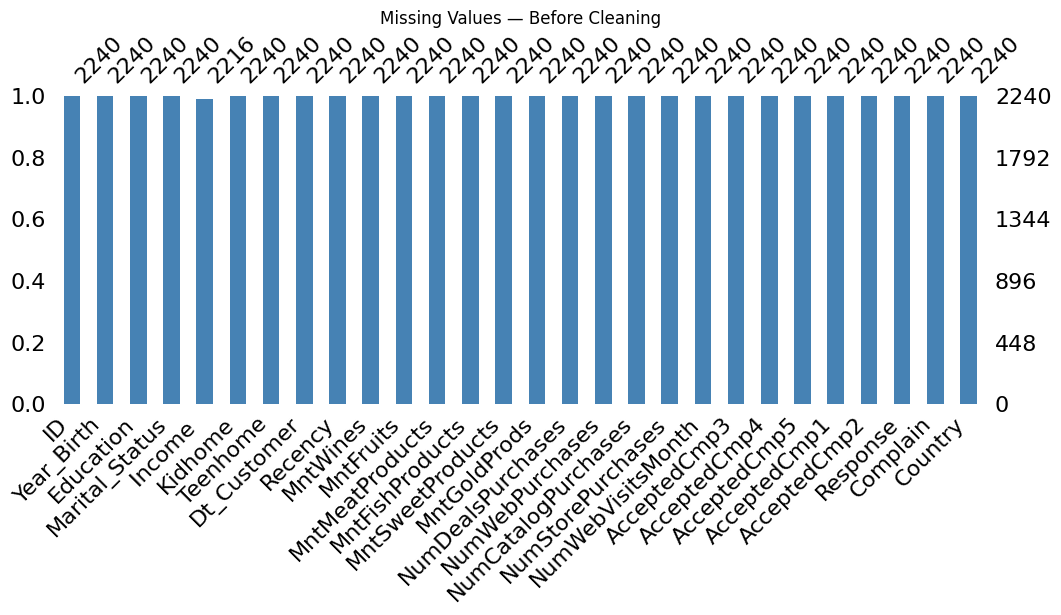

In [51]:
msno.bar(data, figsize=(12, 4), color='steelblue')
plt.title("Missing Values — Before Cleaning")
plt.show()

In [52]:
data.columns = data.columns.str.strip()   # strips spaces from all column names

print("Column names after fix:")
print(list(data.columns))

Column names after fix:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Response', 'Complain', 'Country']


In [53]:
# Step 1: Remove the $ sign
data['Income'] = data['Income'].str.replace('$', '', regex=False)

# Step 2: Remove the commas (84,835 → 84835)
data['Income'] = data['Income'].str.replace(',', '', regex=False)

# Step 3: Convert from text to a decimal number
data['Income'] = data['Income'].astype(float)

# Step 4: Fill the 24 missing values with the median income
data['Income'] = data['Income'].fillna(data['Income'].median())

print("Income fixed!")
print("Missing values remaining:", data['Income'].isnull().sum())
print("Sample values:", data['Income'].head(5).values)

Income fixed!
Missing values remaining: 0
Sample values: [84835. 57091. 67267. 32474. 21474.]


In [54]:
# Get all numeric columns
numeric_cols = data.select_dtypes(include='number').columns.tolist()
print("Numeric columns to check:")
print(numeric_cols)

Numeric columns to check:
['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Response', 'Complain']


In [55]:
data[numeric_cols].describe().round(2)

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain
count,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,...,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00
mean,5592.16,1968.81,52237.98,0.44,0.51,49.11,303.94,26.30,166.95,37.53,...,2.66,5.79,5.32,0.07,0.07,0.07,0.06,0.01,0.15,0.01
std,3246.66,11.98,25037.96,0.54,0.54,28.96,336.60,39.77,225.72,54.63,...,2.92,3.25,2.43,0.26,0.26,0.26,0.25,0.11,0.36,0.10
min,0.00,1893.00,1730.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2828.25,1959.00,35538.75,0.00,0.00,24.00,23.75,1.00,16.00,3.00,...,0.00,3.00,3.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5458.50,1970.00,51381.50,0.00,0.00,49.00,173.50,8.00,67.00,12.00,...,2.00,5.00,6.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,8427.75,1977.00,68289.75,1.00,1.00,74.00,504.25,33.00,232.00,50.00,...,4.00,8.00,7.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
max,11191.00,1996.00,666666.00,2.00,2.00,99.00,1493.00,199.00,1725.00,259.00,...,28.00,13.00,20.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


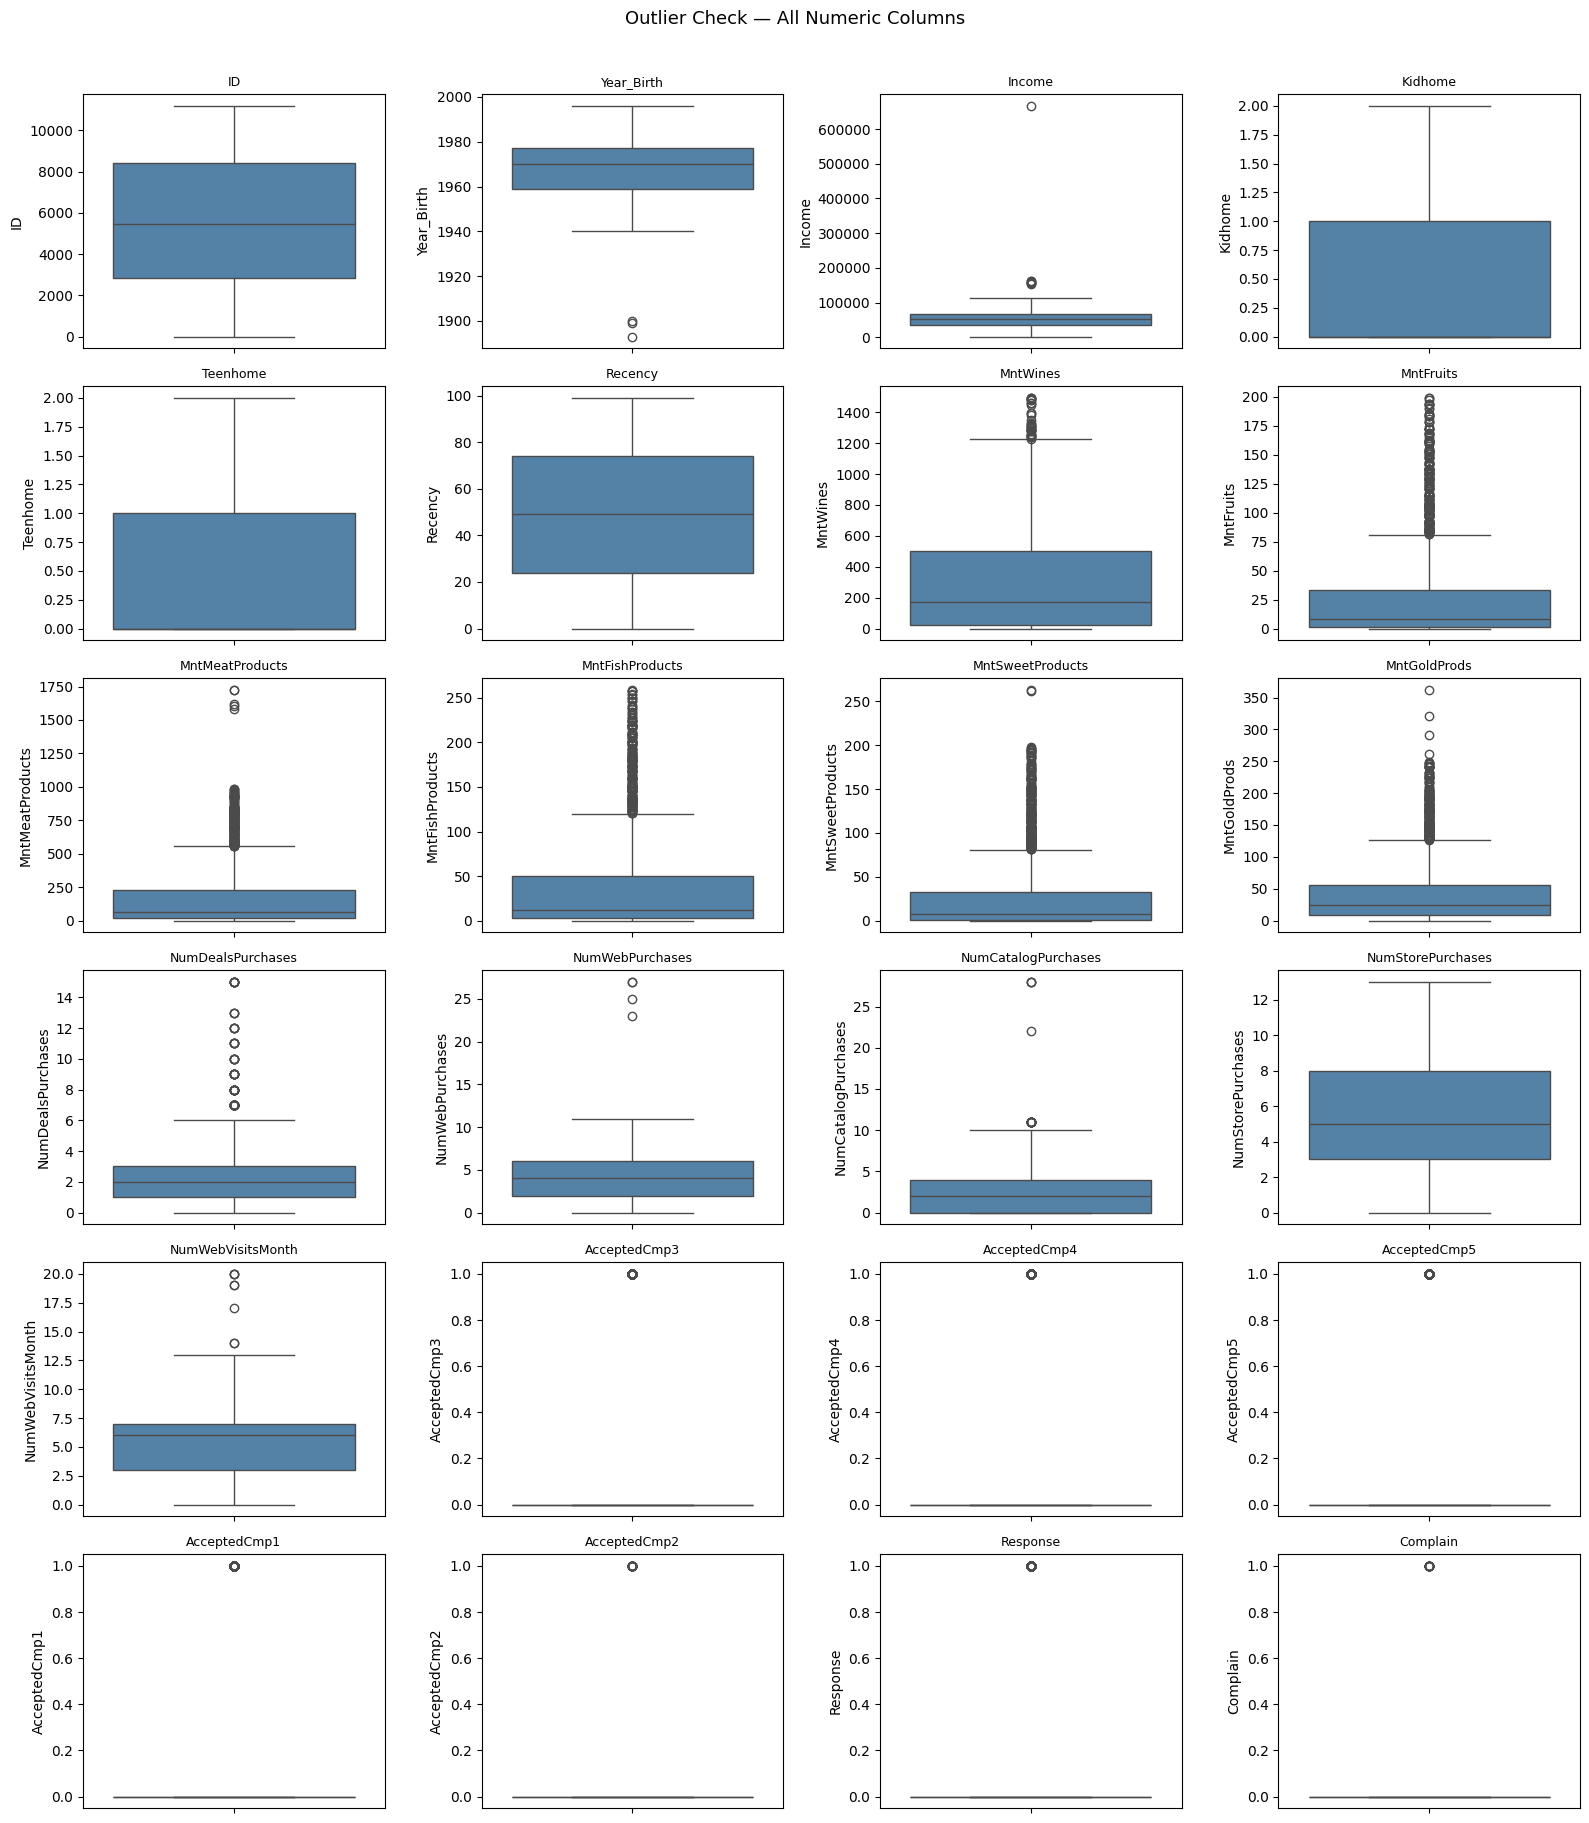

In [56]:
# How many columns we have
n = len(numeric_cols)

# Create a grid of boxplots — 4 per row
cols_per_row = 4
rows = (n + cols_per_row - 1) // cols_per_row

fig, axes = plt.subplots(rows, cols_per_row, figsize=(16, rows * 3))
axes = axes.flatten()   # makes it easy to loop

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=data[col], ax=axes[i], color='steelblue')
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')

# Hide any empty subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Outlier Check — All Numeric Columns", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

In [57]:
print("Outlier count per column (IQR method):\n")

for col in numeric_cols:
    Q1  = data[col].quantile(0.25)
    Q3  = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    outliers = data[(data[col] < lower_fence) | (data[col] > upper_fence)]

    if len(outliers) > 0:
        print(f"  {col:30s}: {len(outliers):4d} outliers  "
              f"(min={data[col].min():.1f}, max={data[col].max():.1f}, "
              f"fence: {lower_fence:.1f} to {upper_fence:.1f})")

Outlier count per column (IQR method):

  Year_Birth                    :    3 outliers  (min=1893.0, max=1996.0, fence: 1932.0 to 2004.0)
  Income                        :    8 outliers  (min=1730.0, max=666666.0, fence: -13587.8 to 117416.2)
  MntWines                      :   35 outliers  (min=0.0, max=1493.0, fence: -697.0 to 1225.0)
  MntFruits                     :  227 outliers  (min=0.0, max=199.0, fence: -47.0 to 81.0)
  MntMeatProducts               :  175 outliers  (min=0.0, max=1725.0, fence: -308.0 to 556.0)
  MntFishProducts               :  223 outliers  (min=0.0, max=259.0, fence: -67.5 to 120.5)
  MntSweetProducts              :  248 outliers  (min=0.0, max=263.0, fence: -47.0 to 81.0)
  MntGoldProds                  :  207 outliers  (min=0.0, max=362.0, fence: -61.5 to 126.5)
  NumDealsPurchases             :   86 outliers  (min=0.0, max=15.0, fence: -2.0 to 6.0)
  NumWebPurchases               :    4 outliers  (min=0.0, max=27.0, fence: -4.0 to 12.0)
  NumCatalogPurc

In [58]:
print("Rows BEFORE:", data.shape[0])

# Calculate Age first using Year_Birth (assuming reference year is 2021)
data['Age'] = 2021 - data['Year_Birth']

# 1. Age — remove impossible ages
data = data[data['Age'] < 90]

# 2. Income — £666,666 is a known extreme outlier in this dataset
#    Remove anyone earning more than £200,000 (clearly an error)
data = data[data['Income'] < 200000]

print("Rows AFTER :", data.shape[0])
print("Removed    :", 2240 - data.shape[0], "rows total")

Rows BEFORE: 2240
Rows AFTER : 2236
Removed    : 4 rows total


In [59]:
# Total money spent across all product categories
spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts',
              'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
data['TotalSpent'] = data[spend_cols].sum(axis=1)

# Total number of purchases across all channels
data['TotalPurchases'] = (data['NumWebPurchases'] +
                           data['NumCatalogPurchases'] +
                           data['NumStorePurchases'])

print("New columns created successfully.")
print(data[['Age', 'TotalSpent', 'TotalPurchases']].describe().round(2))

New columns created successfully.
          Age  TotalSpent  TotalPurchases
count  2236.0     2236.00         2236.00
mean     52.1      605.99           12.55
std      11.7      601.87            7.21
min      25.0        5.00            0.00
25%      44.0       69.00            6.00
50%      51.0      396.50           12.00
75%      62.0     1045.50           18.00
max      81.0     2525.00           32.00


In [60]:
print("Final dataset shape:", data.shape)
print("\nMissing values remaining:")
print(data.isnull().sum()[data.isnull().sum() > 0])
print("\nAll good!" if data.isnull().sum().sum() == 0 else "Fix missing values first!")

Final dataset shape: (2236, 31)

Missing values remaining:
Series([], dtype: int64)

All good!


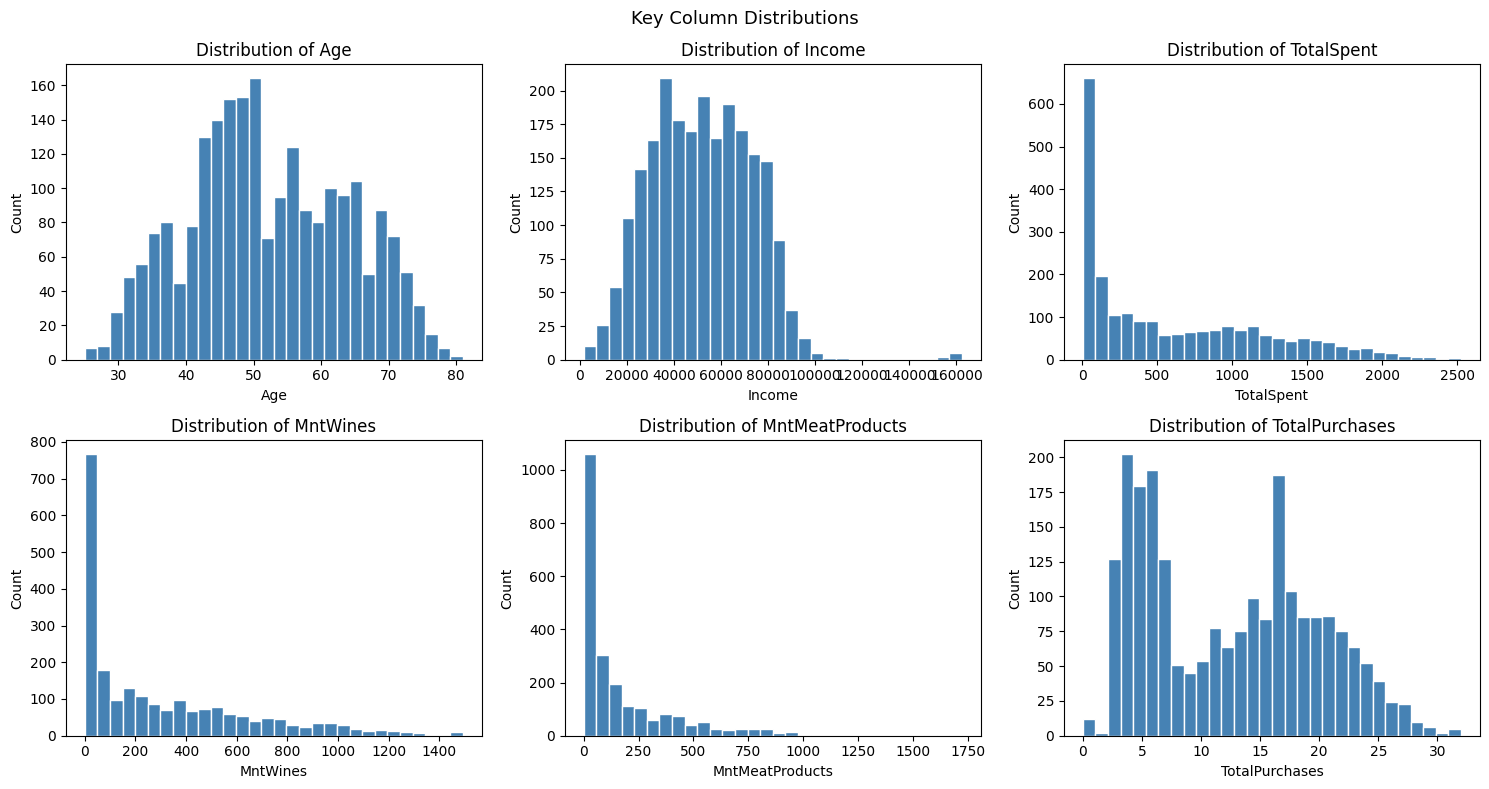

In [61]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

cols_to_plot = ['Age', 'Income', 'TotalSpent',
                'MntWines', 'MntMeatProducts', 'TotalPurchases']

for i, col in enumerate(cols_to_plot):
    axes[i].hist(data[col], bins=30, color='steelblue', edgecolor='white')
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

plt.suptitle("Key Column Distributions", fontsize=13)
plt.tight_layout()
plt.show()

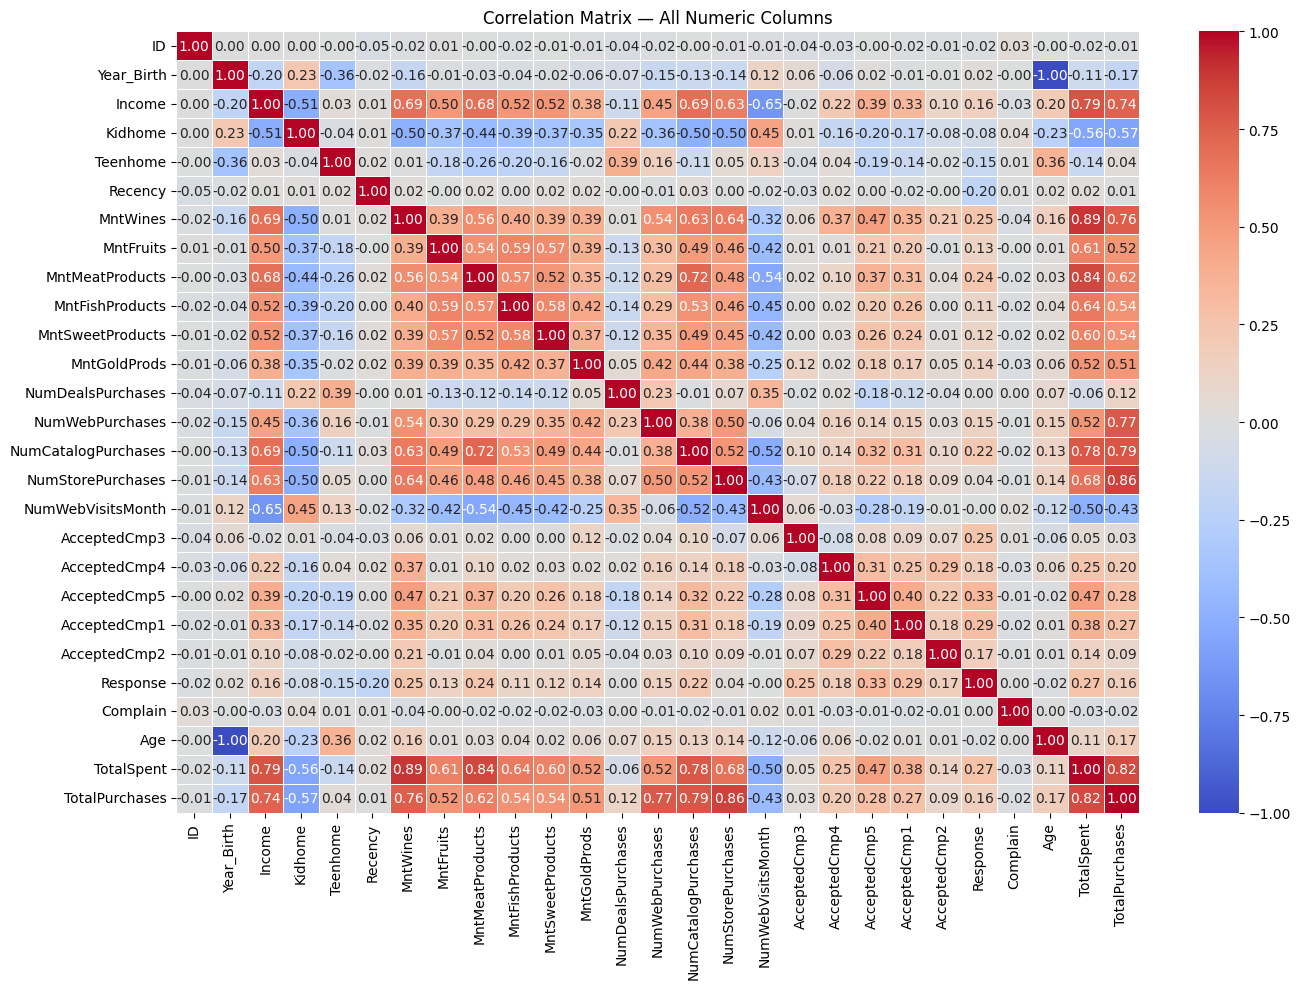

In [62]:
numeric_cols = data.select_dtypes(include='number').columns

plt.figure(figsize=(14, 10))
sns.heatmap(data[numeric_cols].corr(),
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            vmin=-1, vmax=1,
            linewidths=0.5)
plt.title("Correlation Matrix — All Numeric Columns")
plt.tight_layout()
plt.show()

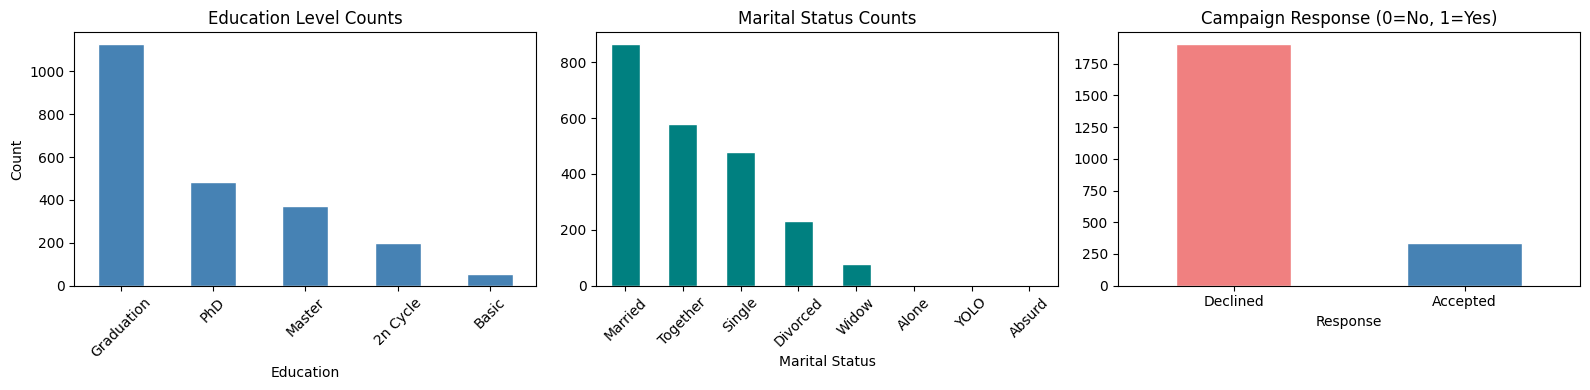

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Education levels
data['Education'].value_counts().plot(kind='bar', ax=axes[0],
                                       color='steelblue', edgecolor='white')
axes[0].set_title("Education Level Counts")
axes[0].set_xlabel("Education")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', rotation=45)

# Marital status
data['Marital_Status'].value_counts().plot(kind='bar', ax=axes[1],
                                            color='teal', edgecolor='white')
axes[1].set_title("Marital Status Counts")
axes[1].set_xlabel("Marital Status")
axes[1].tick_params(axis='x', rotation=45)

# Campaign response
data['Response'].value_counts().plot(kind='bar', ax=axes[2],
                                      color=['lightcoral', 'steelblue'],
                                      edgecolor='white')
axes[2].set_title("Campaign Response (0=No, 1=Yes)")
axes[2].set_xlabel("Response")
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Declined', 'Accepted'], rotation=0)

plt.tight_layout()
plt.show()

In [64]:
from scipy.stats import shapiro

cols_to_test = ['MntWines', 'Income', 'TotalSpent']

print("Shapiro-Wilk Normality Test (p > 0.05 = normal distribution):\n")

for col in cols_to_test:
    stat, p = shapiro(data[col].sample(500, random_state=42))  # sample 500 rows
    result = "Normal ✓" if p > 0.05 else "NOT normal ✗"
    print(f"  {col:20s}: p = {p:.4f}  →  {result}")

Shapiro-Wilk Normality Test (p > 0.05 = normal distribution):

  MntWines            : p = 0.0000  →  NOT normal ✗
  Income              : p = 0.0000  →  NOT normal ✗
  TotalSpent          : p = 0.0000  →  NOT normal ✗


Group summaries:
  PhD   → n=485,  mean=£403.8,  std=£390.4
  Basic → n=54, mean=£7.2,  std=£30.8

T-statistic : 7.4551
P-value     : 0.000000

✓ REJECT H0 — significant difference in wine spending (p ≤ 0.05)


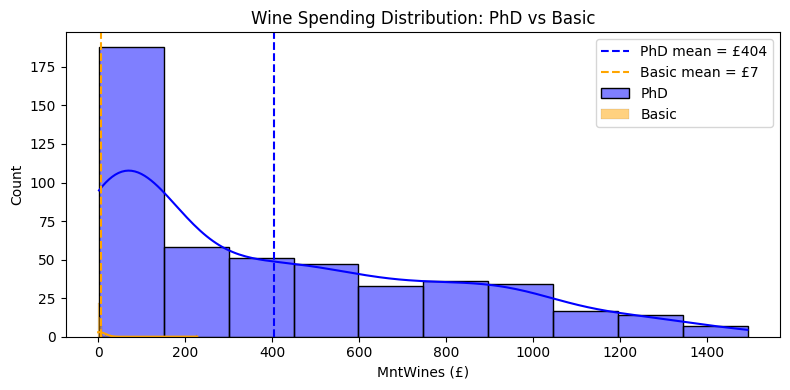

In [65]:
# T-Test

# Question: Do PhD graduates spend more on wine than Basic education customers?
# H0: No difference in wine spending between PhD and Basic customers
# H1: There IS a difference

# Split into two groups
phd   = data[data['Education'] == 'PhD']['MntWines']
basic = data[data['Education'] == 'Basic']['MntWines']

# Print group summaries
print("Group summaries:")
print(f"  PhD   → n={len(phd)},  mean=£{phd.mean():.1f},  std=£{phd.std():.1f}")
print(f"  Basic → n={len(basic)}, mean=£{basic.mean():.1f},  std=£{basic.std():.1f}")

# Run the test
t_stat, p_value = stats.ttest_ind(phd, basic)
print(f"\nT-statistic : {t_stat:.4f}")
print(f"P-value     : {p_value:.6f}")

# Decision
if p_value <= 0.05:
    print("\n✓ REJECT H0 — significant difference in wine spending (p ≤ 0.05)")
else:
    print("\n✗ FAIL TO REJECT H0 — no significant difference (p > 0.05)")

# Visualise
plt.figure(figsize=(8, 4))
sns.histplot(phd,   color='blue',   label='PhD',   kde=True, alpha=0.5)
sns.histplot(basic, color='orange', label='Basic',  kde=True, alpha=0.5)
plt.axvline(phd.mean(),   color='blue',   linestyle='--', label=f'PhD mean = £{phd.mean():.0f}')
plt.axvline(basic.mean(), color='orange', linestyle='--', label=f'Basic mean = £{basic.mean():.0f}')
plt.title("Wine Spending Distribution: PhD vs Basic")
plt.xlabel("MntWines (£)")
plt.legend()
plt.tight_layout()
plt.show()

Mean wine spending by education level:
  Graduation   → n=1126,  mean=£284.5
  PhD          → n= 485,  mean=£403.8
  2n Cycle     → n= 201,  mean=£200.0
  Master       → n= 370,  mean=£333.1
  Basic        → n=  54,  mean=£7.2

F-statistic : 28.9545
P-value     : 0.000000

✓ REJECT H0 — at least one education group spends significantly differently


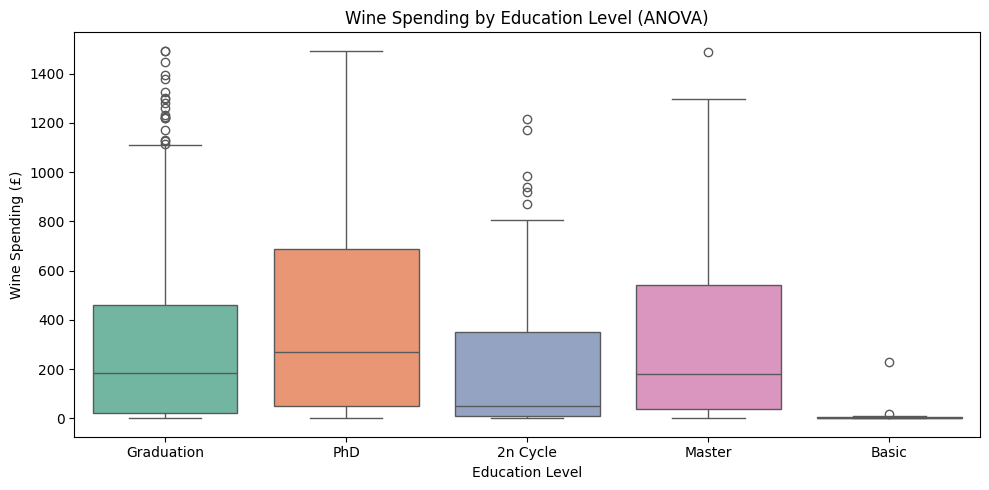

In [66]:
# ANOVA

# Question: Does wine spending differ across ALL five education levels?
# H0: Mean wine spending is equal across all education levels
# H1: At least one group is different

# Create one group per education level
education_levels = data['Education'].unique()
groups = [data[data['Education'] == edu]['MntWines']
          for edu in education_levels]

# Print group means
print("Mean wine spending by education level:")
for edu in education_levels:
    grp = data[data['Education'] == edu]['MntWines']
    print(f"  {edu:12s} → n={len(grp):4d},  mean=£{grp.mean():.1f}")

# Run the test
f_stat, p_value = stats.f_oneway(*groups)
print(f"\nF-statistic : {f_stat:.4f}")
print(f"P-value     : {p_value:.6f}")

# Decision
if p_value <= 0.05:
    print("\n✓ REJECT H0 — at least one education group spends significantly differently")
else:
    print("\n✗ FAIL TO REJECT H0 — no significant difference across groups")

# Visualise
plt.figure(figsize=(10, 5))
sns.boxplot(x=data['Education'], y=data['MntWines'],
            hue=data['Education'], palette='Set2', legend=False)
plt.title("Wine Spending by Education Level (ANOVA)")
plt.xlabel("Education Level")
plt.ylabel("Wine Spending (£)")
plt.tight_layout()
plt.show()

Contingency Table (0 = Declined, 1 = Accepted):
Response      0    1
Education           
2n Cycle    179   22
Basic        52    2
Graduation  974  152
Master      313   57
PhD         384  101

Chi-squared : 23.0116
Degrees of freedom: 4
P-value     : 0.000126

✓ REJECT H0 — education IS related to campaign response


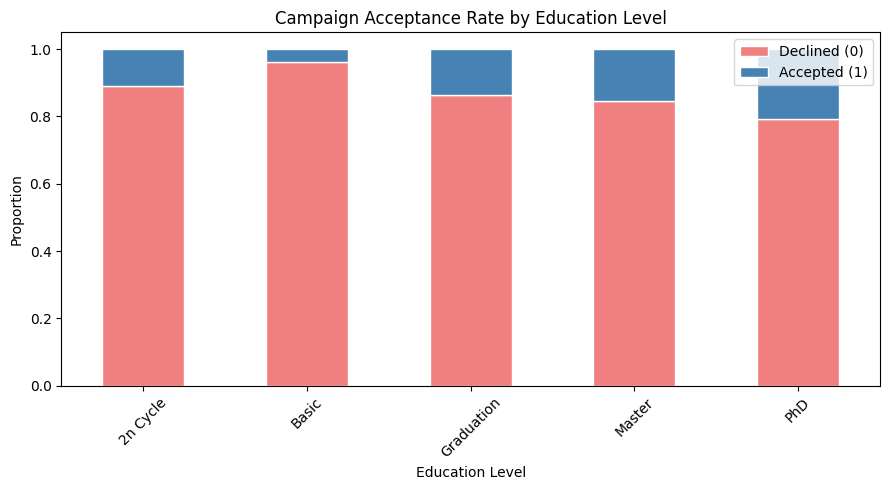

In [67]:
# Chi-Squared Test

# Question: Is education level related to accepting the marketing campaign?
# H0: Education and campaign response are independent (no relationship)
# H1: Education and campaign response ARE related

# Build contingency table
contingency = pd.crosstab(data['Education'], data['Response'])
print("Contingency Table (0 = Declined, 1 = Accepted):")
print(contingency)

# Run the test
chi2_stat, p_value, dof, expected = stats.chi2_contingency(contingency)
print(f"\nChi-squared : {chi2_stat:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value     : {p_value:.6f}")

# Decision
if p_value <= 0.05:
    print("\n✓ REJECT H0 — education IS related to campaign response")
else:
    print("\n✗ FAIL TO REJECT H0 — no significant relationship found")

# Visualise — stacked bar chart
pct = contingency.div(contingency.sum(axis=1), axis=0)
pct.plot(kind='bar', stacked=True, figsize=(9, 5),
         color=['lightcoral', 'steelblue'], edgecolor='white')
plt.title("Campaign Acceptance Rate by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Proportion")
plt.legend(["Declined (0)", "Accepted (1)"], loc='upper right')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Pearson r   : 0.6861
P-value     : 0.000000

✓ REJECT H0 — significant POSITIVE correlation
  Higher income → more wine spending


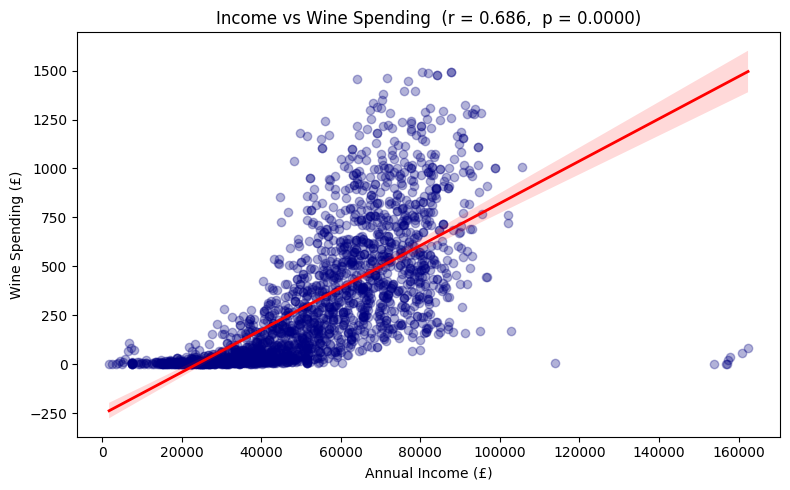

In [68]:
# Correlation Test

# Question: Does higher income lead to more wine spending?
# H0: Income and wine spending are NOT correlated (r = 0)
# H1: Income and wine spending ARE correlated (r ≠ 0)

# Run the test
r, p_value = stats.pearsonr(data['Income'], data['MntWines'])
print(f"Pearson r   : {r:.4f}")
print(f"P-value     : {p_value:.6f}")

# Decision
if p_value <= 0.05:
    direction = "POSITIVE" if r > 0 else "NEGATIVE"
    print(f"\n✓ REJECT H0 — significant {direction} correlation")
    print(f"  Higher income → {'more' if r > 0 else 'less'} wine spending")
else:
    print("\n✗ FAIL TO REJECT H0 — no significant correlation")

# Visualise — scatter plot with regression line
plt.figure(figsize=(8, 5))
sns.regplot(x=data['Income'], y=data['MntWines'],
            scatter_kws={'alpha': 0.3, 'color': 'navy'},
            line_kws={'color': 'red', 'linewidth': 2})
plt.title(f"Income vs Wine Spending  (r = {r:.3f},  p = {p_value:.4f})")
plt.xlabel("Annual Income (£)")
plt.ylabel("Wine Spending (£)")
plt.tight_layout()
plt.show()

In [69]:
print("=" * 55)
print("  HYPOTHESIS TESTING RESULTS SUMMARY")
print("=" * 55)

results = [
    ("T-test",      "PhD vs Basic wine spending",         "Cell 17"),
    ("ANOVA",       "All education vs wine spending",     "Cell 18"),
    ("Chi-Squared", "Education vs campaign response",     "Cell 19"),
    ("Correlation", "Income vs wine spending",            "Cell 20"),
]

for test, question, cell in results:
    print(f"\n  {cell} | {test}")
    print(f"  Question : {question}")
    print(f"  α = 0.05 | Check your p-value above to confirm decision")

print("\n" + "=" * 55)
print("  DECISION RULE:")
print("  p ≤ 0.05  →  REJECT H0  (significant result)")
print("  p > 0.05  →  FAIL TO REJECT H0  (not significant)")
print("=" * 55)

  HYPOTHESIS TESTING RESULTS SUMMARY

  Cell 17 | T-test
  Question : PhD vs Basic wine spending
  α = 0.05 | Check your p-value above to confirm decision

  Cell 18 | ANOVA
  Question : All education vs wine spending
  α = 0.05 | Check your p-value above to confirm decision

  Cell 19 | Chi-Squared
  Question : Education vs campaign response
  α = 0.05 | Check your p-value above to confirm decision

  Cell 20 | Correlation
  Question : Income vs wine spending
  α = 0.05 | Check your p-value above to confirm decision

  DECISION RULE:
  p ≤ 0.05  →  REJECT H0  (significant result)
  p > 0.05  →  FAIL TO REJECT H0  (not significant)
